# Intro to AI Agents: Build the Simplest One

*ABRHS Research Club, Data Science Track*

An **AI agent** works toward a goal in a loop: it decides what to do next, does it with a tool, remembers what it found, and repeats until it can answer. Here's the simplest one, in about 20 lines of Python.

Run the cells from top to bottom with Shift + Enter. Nothing to install, no API key.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Mateiio/GenerativeShift/blob/main/presentations/ABRHSResearchClub/DataScienceTrack/Workshops/IntroToAgents/notebook/IntroToAgents_Workshop_ABRHS_ResearchClub.ipynb)

## 1. What is an agent?

Our agent's **goal**: find a city on our list that's at least 25 °C today, so we can go to the beach.

It can't know the answer in advance. It has to check cities one at a time and decide after each one whether it's done. For that it needs four parts: a **tool** to look things up, a **brain** to decide the next step, **notes** to remember what it found, and a **loop** that keeps going until the brain answers.

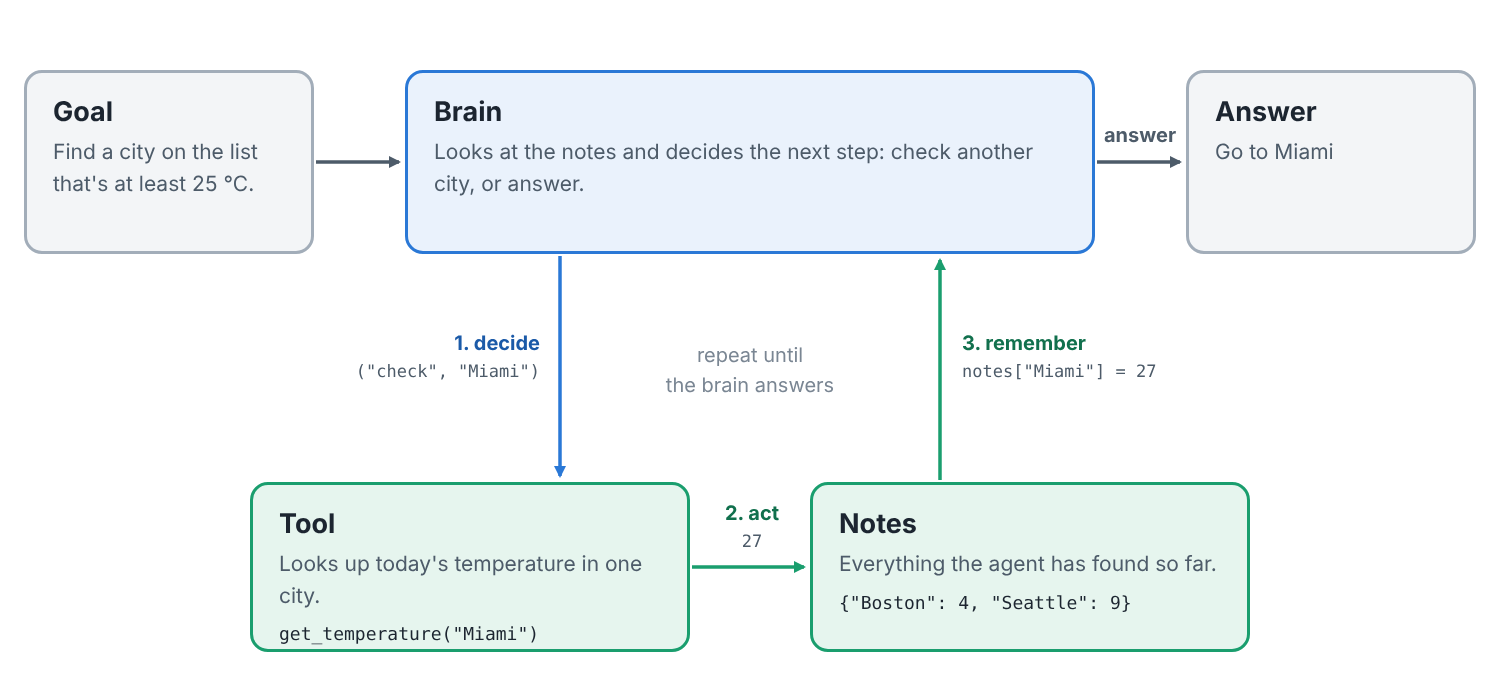

## 2. The agent

Here's the whole agent. Run it.

In [1]:
cities = ["Boston", "Seattle", "Miami", "Denver"]
temperatures = {"Boston": 4, "Seattle": 9, "Miami": 27, "Denver": -3}

def get_temperature(city):         # TOOL: looks something up
    return temperatures[city]

def brain(notes):                  # BRAIN: decides the next step
    for city in notes:
        if notes[city] >= 25:
            return "answer", city
    for city in cities:
        if city not in notes:
            return "check", city

notes = {}                         # NOTES: what the agent has found so far
while True:                        # LOOP: decide, act, remember, repeat
    action, city = brain(notes)
    if action == "answer":
        print("Go to", city)
        break
    notes[city] = get_temperature(city)
    print(city, "is", notes[city], "°C")

Boston is 4 °C
Seattle is 9 °C
Miami is 27 °C
Go to Miami


It checked three cities and stopped. It never looked up Denver, because the brain already had its answer. Nobody told it how many steps to take.

- **Tool:** `get_temperature` looks up one city.
- **Brain:** if a city in the notes is warm enough, answer. Otherwise, check a city that isn't in the notes yet.
- **Notes:** `notes` remembers every temperature found so far.
- **Loop:** `while True` keeps asking the brain, using the tool and updating the notes, until the brain answers.

## 3. Try it yourself

Change the cell above and run it again:

- Put `"Miami"` first in `cities`. How many cities does it check now?
- Change `25` to `0`. Where does it send you?
- Make Miami `20`. Now no city is warm enough, and the agent crashes. Can you add a rule to the brain so it answers `"nowhere"` instead?

## 4. From rules to AI agents

Our brain is a few rules we wrote. In the AI agents behind ChatGPT and Claude, the brain is a **language model**: it reads the goal and the notes, and writes back the next step. The tool, the notes and the loop work the same way.